<a href="https://colab.research.google.com/github/erickcorrea3092/Cheminformatics-course/blob/main/4_1_RDKit_descriptores_single.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

En este tutorial comenzaremos con los primeros pasos en rdKit, empezaremos con las importaciones

#ANTECEDENTES


In [1]:
! pip install rdkit
from rdkit import Chem
import rdkit
rdkit.__version__

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 25.8 MB/s eta 0:00:00


'2026.09.1'

#DATOS

Renderizamos las estructuras con el paquete rdkit.chem una molécula de prueba a partir de SMILES



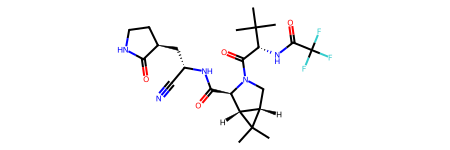

In [2]:
nirmatrevir = Chem.MolFromSmiles('CC1([C@@H]2[C@H]1[C@H](N(C2)C(=O)[C@H](C(C)(C)C)NC(=O)C(F)(F)F)C(=O)N[C@@H](C[C@@H]3CCNC3=O)C#N)C')
nirmatrevir

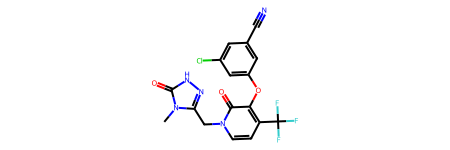

In [3]:
doravirine = Chem.MolFromSmiles('Cn1c(n[nH]c1=O)Cn2ccc(c(c2=O)Oc3cc(cc(c3)Cl)C#N)C(F)(F)F')
doravirine

#CÁLCULO DE DESCRIPTORES

El módulo Descriptores tiene una lista de los descriptores disponibles. La lista está formada por (nombre, función) 2-tuplas:

In [4]:
from rdkit.Chem import Descriptors
print(len(Descriptors._descList))
print(Descriptors._descList[:216]) #calcula desde el descriptor 0 hasta el 211

217
[('MaxAbsEStateIndex', <function MaxAbsEStateIndex at 0x7a0ef0ab4360>), ('MaxEStateIndex', <function MaxEStateIndex at 0x7a0ef0ab4220>), ('MinAbsEStateIndex', <function MinAbsEStateIndex at 0x7a0ef0ab4400>), ('MinEStateIndex', <function MinEStateIndex at 0x7a0ef0ab42c0>), ('qed', <function qed at 0x7a0ef0ab74c0>), ('SPS', <function SPS at 0x7a0ef0ab79c0>), ('MolWt', <function <lambda> at 0x7a0ef0ab7920>), ('HeavyAtomMolWt', <function HeavyAtomMolWt at 0x7a0ef0ac8180>), ('ExactMolWt', <function <lambda> at 0x7a0ef0ac8220>), ('NumValenceElectrons', <function NumValenceElectrons at 0x7a0ef0ac82c0>), ('NumRadicalElectrons', <function NumRadicalElectrons at 0x7a0ef0ac8360>), ('MaxPartialCharge', <function MaxPartialCharge at 0x7a0ef0ac84a0>), ('MinPartialCharge', <function MinPartialCharge at 0x7a0ef0ac8540>), ('MaxAbsPartialCharge', <function MaxAbsPartialCharge at 0x7a0ef0ac85e0>), ('MinAbsPartialCharge', <function MinAbsPartialCharge at 0x7a0ef0ac8680>), ('FpDensityMorgan1', <functio

Podemos usar esas funciones para calcular directamente el descriptor correspondiente. Así, por ejemplo, el valor de MaxEStateIndex para doravirina es:

In [5]:
#Esta es una lista interna del módulo rdkit.Chem.Descriptors que contiene tuplas.
#Cada tupla tiene el nombre de un descriptor y la función Python asociada para calcularlo.

# [0] Accede al elemento número 0 de esa lista.

#[1]: De la tupla seleccionada, [1] accede a la segunda parte, que es la función Python para calcular el descriptor

Descriptors._descList[0][1](doravirine)#[0] es la posición en la lista, [1] es la posión de la molécula

np.float64(13.412553309006833)

In [6]:
Descriptors._descList[0] #confirmamos que se trata de ese descriptor invocandolo con su posición en la lista

('MaxAbsEStateIndex',
 <function rdkit.Chem.EState.EState.MaxAbsEStateIndex(mol, force=1)>)

In [7]:
print(Descriptors._descList[34][1](doravirine))
print(Descriptors._descList[34]) #confirmamos que se trata de ese descriptor invocandolo con su posición en la lista

8.271283703809537
('Chi1v', <function <lambda> at 0x7a0ef0ad6fc0>)


Ahora calculamos los descriptores para el nirmatrevir

In [8]:
print(Descriptors._descList[0][1](nirmatrevir)) #calculamos el descriptor a partir de su posición en la lista
print(Descriptors._descList[0]) #confirmamos que se trata de ese descriptor invocandolo con su posición en la lista
print(Descriptors._descList[145][1](nirmatrevir))
print(Descriptors._descList[145])

13.469540519171654
('MaxAbsEStateIndex', <function MaxAbsEStateIndex at 0x7a0ef0ab4360>)
0
('fr_HOCCN', <function _LoadPatterns.<locals>.<lambda> at 0x7a0ef0ad5440>)


Observa que el [0] indica la posición en la lista Descriptors._descList[:211] pero si quisiera otro descriptor es necesario invocarlo de su posición en la lista

In [9]:
Descriptors._descList[8][1](doravirine)

425.050251552

In [10]:
str(Descriptors._descList[8])

"('ExactMolWt', <function <lambda> at 0x7a0ef0ac8220>)"

Además, si solo queremos algunos descriptores con nombre, es mucho más claro (¡y más fácil escribir el código!) si llamamos directamente a las funciones de los descriptores individuales:

In [11]:
Descriptors.MolWt(doravirine)

425.754

In [12]:
Descriptors.SlogP_VSA1(doravirine)

15.98587324705553

In [13]:
print(Descriptors.SlogP_VSA1(nirmatrevir))
print(Descriptors.MolWt(nirmatrevir))

15.950365812018994
499.5340000000003


In [14]:
print('Aquí tienes el resultado Erick, SlogP_VSA1 = '+str( Descriptors.SlogP_VSA1(nirmatrevir)))
print('MolWt = ' + str(Descriptors.MolWt(nirmatrevir)))

Aquí tienes el resultado Erick, SlogP_VSA1 = 15.950365812018994
MolWt = 499.5340000000003


A menudo queremos calcular todos los descriptores. A partir de la versión 2022.09 del rdkit, no existe una función de conveniencia real para el cálculo de descriptores, así que creemos una:

In [15]:
def getMolDescriptors(mol, missingVal=None):
    ''' calcula la lista completa de descriptores de una molécula.
        missingVal usado si el valor no puede ser calculado, por defecto es None.'''

    #  Este diccionario almacenará los nombres de los descriptores como claves keys y sus valores calculados como values.
    res = {}

    # Itera sobre la lista interna Descriptors._descList de RDKit.
    # Cada elemento en _descList es una tupla que contiene:
       # nm: El nombre del descriptor (un string).
       # fn: La función Python asociada que calcula ese descriptor.
    for nm,fn in Descriptors._descList:
        #  Inicia un bloque try-except para manejar posibles errores.
        try:
            val = fn(mol)
            # Intenta llamar a la función fn (la función del descriptor actual)
            # y le pasa la molécula mol para calcular su valor. El resultado se almacena en val.
        except:
            #  Si ocurre un error durante el cálculo del descriptor en el bloque try

            # Estas líneas importan el módulo traceback e imprimen la información completa del error en la consola
            import traceback
            traceback.print_exc()

            val = missingVal # Establece el valor del descriptor val al missingVal especificado
        res[nm] = val # Almacena el valor calculado (o missingVal) en el diccionario res, usando el nombre del descriptor (nm) como clave.
    # la función devuelve el diccionario res que contiene todos los descriptores calculados para la molécula.
    return res


In [16]:
getMolDescriptors(doravirine)

{'MaxAbsEStateIndex': np.float64(13.412553309006833),
 'MaxEStateIndex': np.float64(13.412553309006833),
 'MinAbsEStateIndex': np.float64(0.045220418860841605),
 'MinEStateIndex': np.float64(-4.871620672188628),
 'qed': 0.6914051268589834,
 'SPS': 11.310344827586206,
 'MolWt': 425.754,
 'HeavyAtomMolWt': 414.66600000000005,
 'ExactMolWt': 425.050251552,
 'NumValenceElectrons': 150,
 'NumRadicalElectrons': 0,
 'MaxPartialCharge': 0.4197525104273902,
 'MinPartialCharge': -0.45079941098947357,
 'MaxAbsPartialCharge': 0.45079941098947357,
 'MinAbsPartialCharge': 0.4197525104273902,
 'FpDensityMorgan1': 1.3103448275862069,
 'FpDensityMorgan2': 2.0344827586206895,
 'FpDensityMorgan3': 2.6206896551724137,
 'BCUT2D_MWHI': 35.495691906445956,
 'BCUT2D_MWLOW': 10.182401353178236,
 'BCUT2D_CHGHI': 2.363442602497937,
 'BCUT2D_CHGLO': -2.1532454345808074,
 'BCUT2D_LOGPHI': 2.362094239067197,
 'BCUT2D_LOGPLOW': -2.2620565247489415,
 'BCUT2D_MRHI': 6.30376236817795,
 'BCUT2D_MRLOW': -0.13831572005086

In [17]:
getMolDescriptors(nirmatrevir)

{'MaxAbsEStateIndex': np.float64(13.469540519171654),
 'MaxEStateIndex': np.float64(13.469540519171654),
 'MinAbsEStateIndex': np.float64(0.039554083207357094),
 'MinEStateIndex': np.float64(-5.164441468965123),
 'qed': 0.5037264667056948,
 'SPS': 28.885714285714286,
 'MolWt': 499.5340000000003,
 'HeavyAtomMolWt': 467.27800000000025,
 'ExactMolWt': 499.240639164,
 'NumValenceElectrons': 194,
 'NumRadicalElectrons': 0,
 'MaxPartialCharge': 0.47068428428324405,
 'MinPartialCharge': -0.3558373943158056,
 'MaxAbsPartialCharge': 0.47068428428324405,
 'MinAbsPartialCharge': 0.3558373943158056,
 'FpDensityMorgan1': 1.2285714285714286,
 'FpDensityMorgan2': 1.8571428571428572,
 'FpDensityMorgan3': 2.342857142857143,
 'BCUT2D_MWHI': 19.413378797346933,
 'BCUT2D_MWLOW': 9.847243647456942,
 'BCUT2D_CHGHI': 2.6953089643371535,
 'BCUT2D_CHGLO': -2.3746901812115753,
 'BCUT2D_LOGPHI': 2.6458213073764134,
 'BCUT2D_LOGPLOW': -2.606009413685514,
 'BCUT2D_MRHI': 5.94612354997113,
 'BCUT2D_MRLOW': -0.17591

Tomado originalmente de: https://greglandrum.github.io/rdkit-blog/posts/2022-12-23-descriptor-tutorial.html Adaptado por el Dr. Erick Correa para el curso de Desarrollo de Fármacos Asistido por Computadora Laboratorio de Síntesis de Fármacos L-9, F.E.S. Zaragoza UNAM